Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


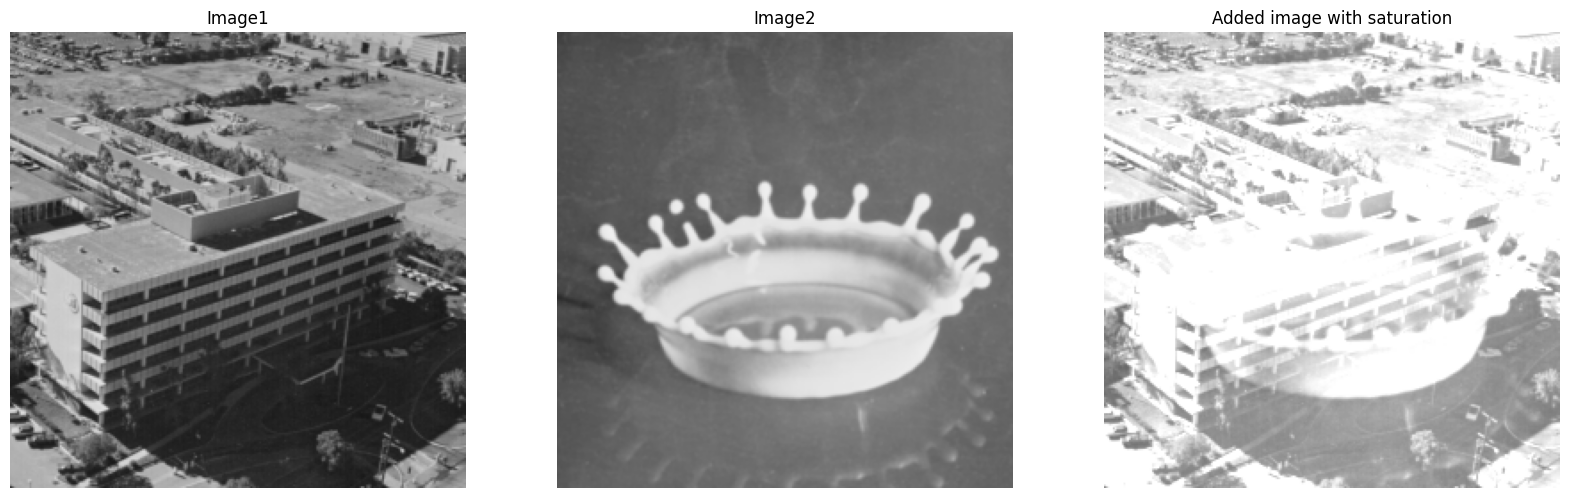

In [18]:
from google.colab.patches import cv2_imshow
from google.colab import drive
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os

drive.mount('/content/gdrive')

# 실제 파일들이 위치한 구글 드라이브 최상위 경로로 업데이트
img1_path = '/content/gdrive/MyDrive/aero2.bmp'
img2_path = '/content/gdrive/MyDrive/milkdrop.bmp'

# 파일 존재 여부 확인
if not os.path.exists(img1_path):
    print(f"⚠️ 이미지 1 파일이 없습니다: {img1_path}")
if not os.path.exists(img2_path):
    print(f"⚠️ 이미지 2 파일이 없습니다: {img2_path}")

img1 = cv2.imread(img1_path)
img2 = cv2.imread(img2_path)

# 이미지 로드 성공 여부 검증
if img1 is None:
    raise FileNotFoundError(f"{img1_path} 이미지를 불러올 수 없습니다. 경로를 확인하세요.")
if img2 is None:
    raise FileNotFoundError(f"{img2_path} 이미지를 불러올 수 없습니다. 경로를 확인하세요.")

# 두 이미지 크기가 다를 경우 크기 맞춤
if img1.shape != img2.shape:
    img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))

RGB_img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
RGB_img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

# 고속 포화 연산(Saturation) 수행
output_img = cv2.add(RGB_img1, RGB_img2)

plt.figure(figsize=(20, 20))

plt.subplot(1, 3, 1)
plt.title("Image1")
plt.imshow(RGB_img1)
plt.axis("off")

plt.subplot(1, 3, 2)
plt.title("Image2")
plt.imshow(RGB_img2)
plt.axis("off")

plt.subplot(1, 3, 3)
plt.title("Added image with saturation")
plt.imshow(output_img)
plt.axis("off")

plt.show()

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


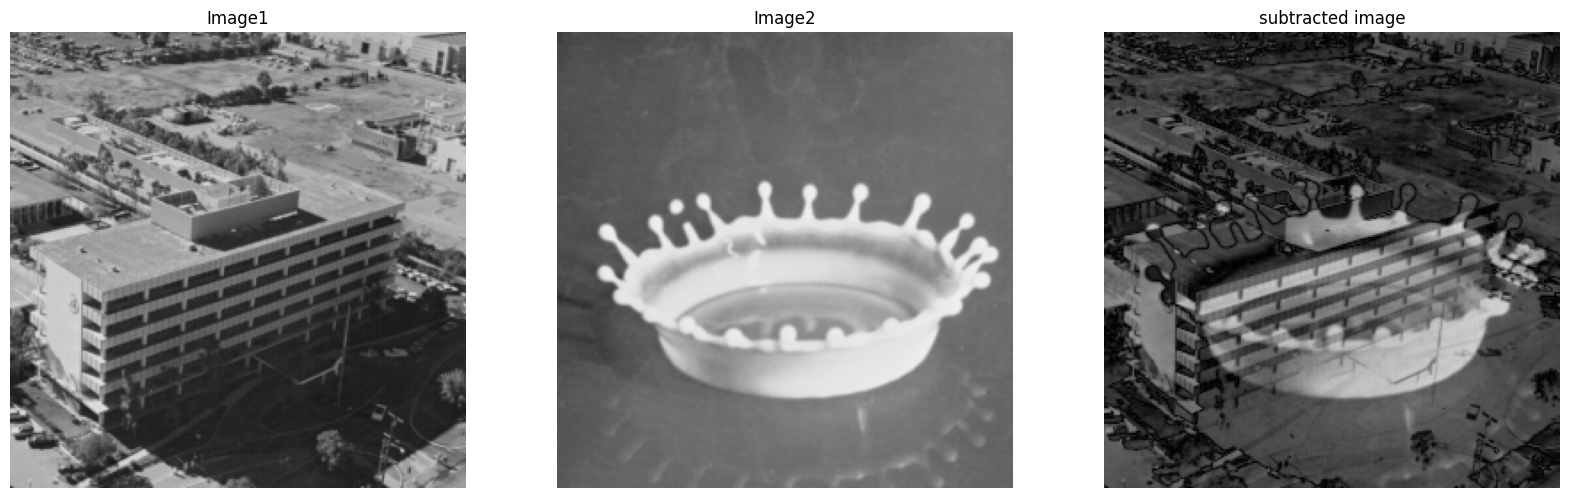

In [20]:
from google.colab.patches import cv2_imshow
from google.colab import drive
import numpy as np
import cv2
import matplotlib.pyplot as plt

drive.mount('/content/gdrive')

# 실제 파일들이 위치한 구글 드라이브 최상위 경로로 수정
img1_path = '/content/gdrive/MyDrive/aero2.bmp'
img2_path = '/content/gdrive/MyDrive/milkdrop.bmp'

img1 = cv2.imread(img1_path)
img2 = cv2.imread(img2_path)

# 이미지 로드 실패 처리
if img1 is None or img2 is None:
    raise FileNotFoundError("이미지 파일을 찾을 수 없습니다. 경로를 확인하세요.")

# 이미지 크기가 다를 경우 크기 맞춤
if img1.shape != img2.shape:
    img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))

RGB_img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
RGB_img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
output_img = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)

R_img1, G_img1, B_img1 = cv2.split(RGB_img1)
R_img2, G_img2, B_img2 = cv2.split(RGB_img2)

R_plus = np.zeros((RGB_img1.shape[0], RGB_img1.shape[1]), dtype=np.ubyte)
G_plus = np.zeros((RGB_img1.shape[0], RGB_img1.shape[1]), dtype=np.ubyte)
B_plus = np.zeros((RGB_img1.shape[0], RGB_img1.shape[1]), dtype=np.ubyte)

for h in range(RGB_img1.shape[0]):
    for w in range(RGB_img1.shape[1]):
        R_plus[h, w] = np.abs(np.int32(R_img1[h, w]) - np.int32(R_img2[h, w]))
        G_plus[h, w] = np.abs(np.int32(G_img1[h, w]) - np.int32(G_img2[h, w]))
        B_plus[h, w] = np.abs(np.int32(B_img1[h, w]) - np.int32(B_img2[h, w]))

plt.figure(figsize=(20, 20))

plt.subplot(1, 3, 1)
plt.title("Image1")
plt.imshow(RGB_img1)
plt.axis("off")

plt.subplot(1, 3, 2)
plt.title("Image2")
plt.imshow(RGB_img2)
plt.axis("off")

plt.subplot(1, 3, 3)
output_img[:, :, 0] = R_plus
output_img[:, :, 1] = G_plus
output_img[:, :, 2] = B_plus
plt.title("subtracted image")
plt.imshow(output_img)
plt.axis("off")

plt.show()